In [201]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.model_selection import GridSearchCV


In [185]:
df = pd.read_csv('Ecommerce_Sales_Prediction_Dataset.csv')

# Load Dataset 

In [3]:
df.head()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17


# Explore the Dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              1000 non-null   object 
 1   Product_Category  1000 non-null   object 
 2   Price             1000 non-null   float64
 3   Discount          1000 non-null   float64
 4   Customer_Segment  1000 non-null   object 
 5   Marketing_Spend   1000 non-null   float64
 6   Units_Sold        1000 non-null   int64  
dtypes: float64(3), int64(1), object(3)
memory usage: 54.8+ KB


In [5]:
df.shape

(1000, 7)

In [6]:
df.describe()

,Price,Discount,Marketing_Spend,Units_Sold
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,505.241920,24.919750,4912.830240,29.631000
std,289.791248,14.439951,2840.602656,7.267989
min,14.590000,0.010000,100.300000,5.000000
25%,243.342500,12.995000,2413.020000,24.000000
50%,509.310000,24.965000,4837.245000,30.000000
75%,747.592500,37.562500,7319.675000,34.000000
max,999.420000,49.920000,9995.620000,57.000000


In [7]:
df.isnull().sum()

Date                0
Product_Category    0
Price               0
Discount            0
Customer_Segment    0
Marketing_Spend     0
Units_Sold          0
dtype: int64

In [8]:
df.drop_duplicates()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,01-01-2023,Sports,932.80,35.82,Occasional,6780.38,32
1,02-01-2023,Toys,569.48,3.60,Premium,6807.56,16
2,03-01-2023,Home Decor,699.68,3.56,Premium,3793.91,27
3,04-01-2023,Toys,923.27,0.61,Premium,9422.75,29
4,05-01-2023,Toys,710.17,47.83,Premium,1756.83,17
...,...,...,...,...,...,...,...
995,22-09-2025,Fashion,740.06,49.06,Regular,1890.83,34
996,23-09-2025,Electronics,517.10,28.48,Premium,8011.66,21
997,24-09-2025,Electronics,683.43,12.98,Occasional,3408.51,19
998,25-09-2025,Sports,51.26,21.85,Occasional,7335.62,26


In [ ]:
# Data Visualiztion  

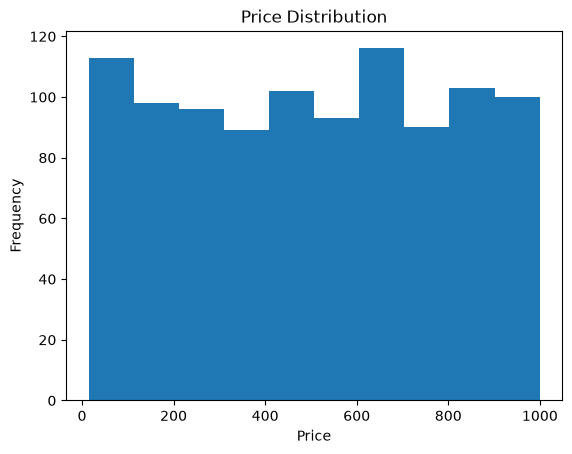

In [9]:
plt.hist(df['Price'],bins=10) 
plt.title('Price Distribution') 
plt.xlabel('Price') 
plt.ylabel('Frequency')
plt.show()


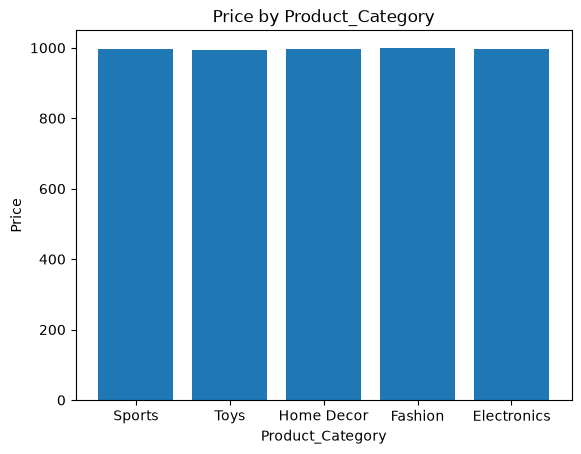

In [10]:
plt.bar(df['Product_Category'],df['Price']) 
plt.title('Price by Product_Category') 
plt.xlabel('Product_Category') 
plt.ylabel('Price')
plt.show()


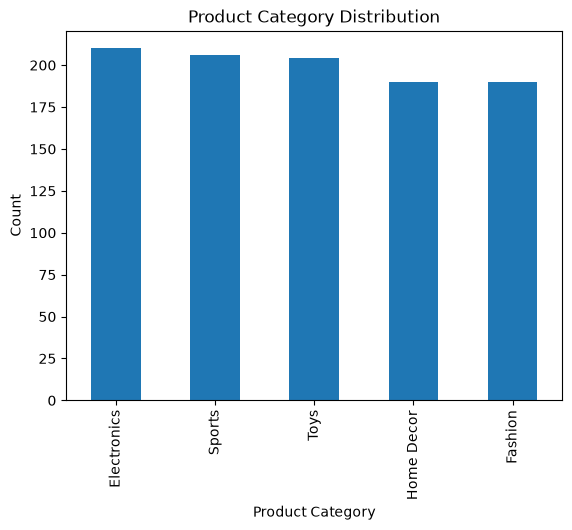

In [11]:
df['Product_Category'].value_counts().plot(kind='bar') 

plt.title('Product Category Distribution') 
plt.xlabel('Product Category') 
plt.ylabel('Count') 
plt.show()

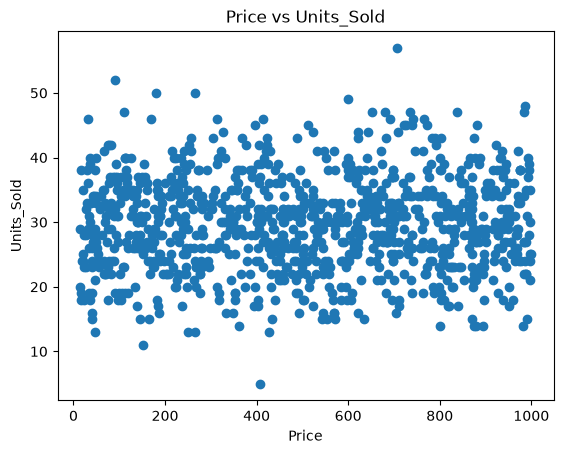

In [12]:
plt.scatter(df['Price'],df['Units_Sold']) 
plt.title('Price vs Units_Sold') 
plt.xlabel('Price') 
plt.ylabel('Units_Sold')
plt.show()




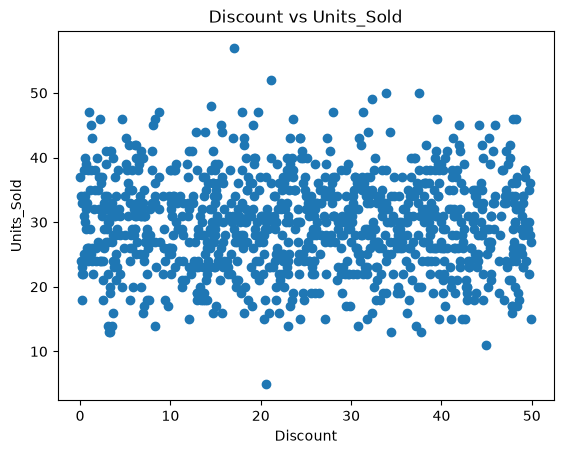

In [13]:
plt.scatter(df['Discount'],df['Units_Sold']) 
plt.title('Discount vs Units_Sold') 
plt.xlabel('Discount') 
plt.ylabel('Units_Sold')
plt.show()



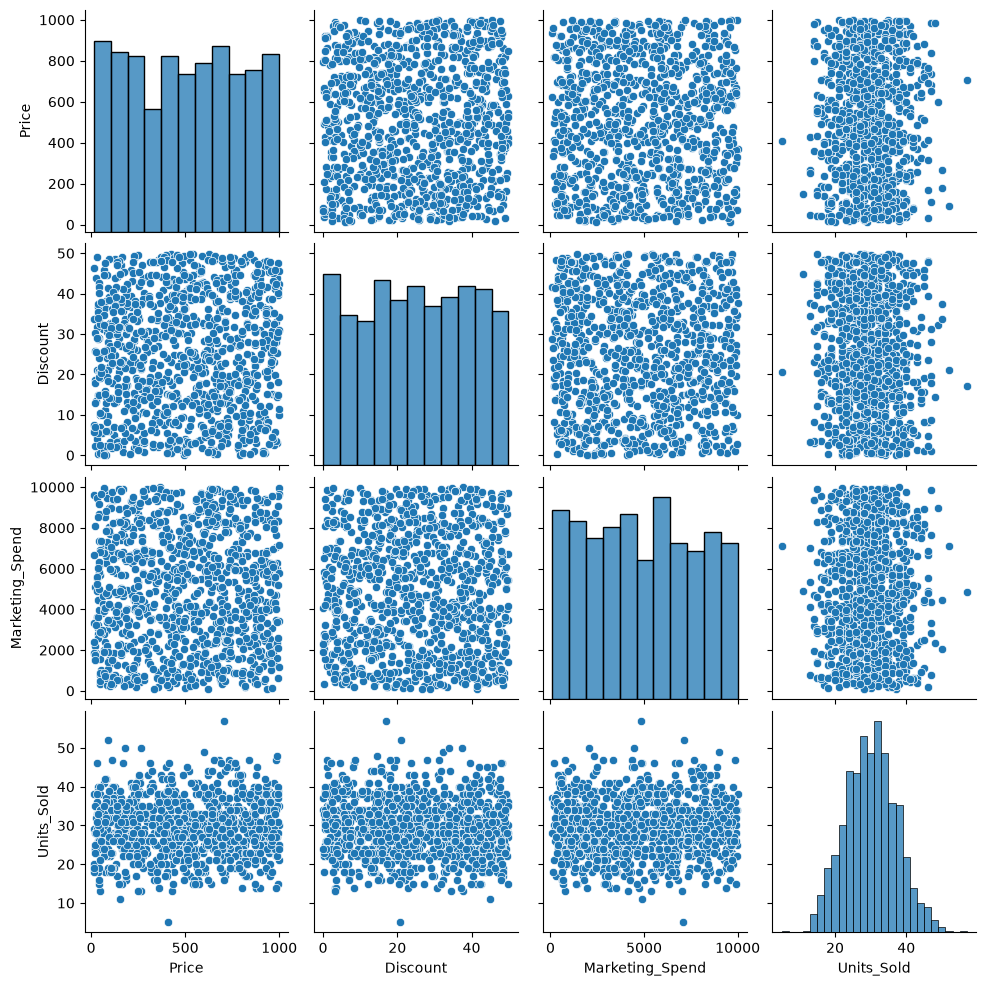

In [14]:
sns.pairplot(df) 
plt.show()

# Data Cleaning and Feature Engineering


In [78]:
print(df.columns.tolist)

<bound method IndexOpsMixin.tolist of Index(['_d_a_t_e_', '_p_r_o_d_u_c_t___c_a_t_e_g_o_r_y_', '_p_r_i_c_e_',
       '_d_i_s_c_o_u_n_t_', '_c_u_s_t_o_m_e_r___s_e_g_m_e_n_t_',
       '_m_a_r_k_e_t_i_n_g___s_p_e_n_d_', '_u_n_i_t_s___s_o_l_d_'],
      dtype='object')>


In [82]:
df['Date'] = pd.to_datetime(df['Date'],errors='coerce')

In [24]:
df.isnull().sum()

Date                604
Product_Category      0
Price                 0
Discount              0
Customer_Segment      0
Marketing_Spend       0
Units_Sold            0
dtype: int64

In [26]:
df = df.drop_duplicates() 
df

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold
0,2023-01-01,Sports,932.80,35.82,Occasional,6780.38,32
1,2023-02-01,Toys,569.48,3.60,Premium,6807.56,16
2,2023-03-01,Home Decor,699.68,3.56,Premium,3793.91,27
3,2023-04-01,Toys,923.27,0.61,Premium,9422.75,29
4,2023-05-01,Toys,710.17,47.83,Premium,1756.83,17
...,...,...,...,...,...,...,...
995,NaT,Fashion,740.06,49.06,Regular,1890.83,34
996,NaT,Electronics,517.10,28.48,Premium,8011.66,21
997,NaT,Electronics,683.43,12.98,Occasional,3408.51,19
998,NaT,Sports,51.26,21.85,Occasional,7335.62,26


In [72]:
df = df.sort_values('Date').reset_index(drop=True)

In [83]:
df['year'] = df['Date'].dt.year 
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day 
df['day_of_week'] = df['Date'].dt.dayofweek 
df['quarter'] = df['Date'].dt.quarter

In [29]:
df.head()

,Date,Product_Category,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold,year,month,day,day_of_week,quarter
0,2023-01-01,Sports,932.80,35.82,Occasional,6780.38,32,2023.0,1.0,1.0,6.0,1.0
1,2023-01-02,Sports,353.48,48.42,Premium,2842.42,19,2023.0,1.0,2.0,0.0,1.0
2,2023-01-03,Fashion,198.78,12.61,Regular,3419.26,24,2023.0,1.0,3.0,1.0,1.0
3,2023-01-04,Home Decor,656.22,0.47,Occasional,8109.33,31,2023.0,1.0,4.0,2.0,1.0
4,2023-01-05,Fashion,301.52,44.31,Premium,5426.42,33,2023.0,1.0,5.0,3.0,1.0


In [135]:
df['lag_1'] = df.groupby('Product_Category')['Units_Sold'].shift(1)
df['lag_7'] = df.groupby('Product_Category')['Units_Sold'].shift(7) 
df['lag_30'] = df.groupby('Product_Category')['Units_Sold'].shift(30)

In [136]:
df['rolling_7'] =  df.groupby('Product_Category')['Units_Sold'].transform(
    lambda x: 
    x.shift(1).rolling(7).mean()
) 

df['rolling_30'] =  df.groupby('Product_Category')['Units_Sold'].transform(
    lambda x: 
    x.shift(1).rolling(30).mean()
) 

In [137]:
df[['Date','Product_Category','Units_Sold','lag_1','lag_7','lag_30','rolling_7','rolling_30']].head(40)

,Date,Product_Category,Units_Sold,lag_1,lag_7,lag_30,rolling_7,rolling_30
0,01-01-2023,Sports,32,NaN,NaN,NaN,NaN,NaN
1,02-01-2023,Toys,16,NaN,NaN,NaN,NaN,NaN
2,03-01-2023,Home Decor,27,NaN,NaN,NaN,NaN,NaN
3,04-01-2023,Toys,29,16.0,NaN,NaN,NaN,NaN
4,05-01-2023,Toys,17,29.0,NaN,NaN,NaN,NaN
5,06-01-2023,Fashion,27,NaN,NaN,NaN,NaN,NaN
6,07-01-2023,Home Decor,30,27.0,NaN,NaN,NaN,NaN
7,08-01-2023,Home Decor,27,30.0,NaN,NaN,NaN,NaN
8,09-01-2023,Home Decor,32,27.0,NaN,NaN,NaN,NaN
9,10-01-2023,Toys,28,17.0,NaN,NaN,NaN,NaN


In [138]:
df = df.dropna().reset_index(drop=True)

In [139]:
df = pd.get_dummies(
    df, 
    columns=[
        'Product_Category' 
    
        
        
    ], 
    dtype=int
)

In [140]:
df.head()

,Date,Price,Discount,Customer_Segment,Marketing_Spend,Units_Sold,lag_1,lag_7,lag_30,rolling_7,rolling_30,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys
0,06-05-2023,492.56,0.16,Regular,2032.15,22,29.0,40.0,32.0,28.714286,28.366667,0,0,0,1,0
1,08-05-2023,801.86,17.77,Occasional,7442.25,19,22.0,15.0,26.0,26.142857,28.033333,0,0,0,1,0
2,13-05-2023,637.14,32.12,Premium,8611.97,33,19.0,33.0,27.0,26.714286,27.800000,0,0,0,1,0
3,17-05-2023,984.56,28.03,Regular,7648.22,47,33.0,32.0,20.0,26.714286,28.000000,0,0,0,1,0
4,23-05-2023,126.57,24.91,Premium,5835.21,35,47.0,28.0,17.0,28.857143,28.900000,0,0,0,1,0


In [44]:
df.columns = df.columns.str.strip().str.lower().str.replace('','_')

# Select X and Y 

In [88]:
x = df.drop(['Date','Units_Sold'],axis=1) 

y = df['Units_Sold']

In [89]:
x.head()

,Price,Discount,Customer_Segment,Marketing_Spend,year,month,day,day_of_week,quarter,lag_1,lag_7,lag_30,rolling_7,rolling_30,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys
0,492.56,0.16,Regular,2032.15,2023.0,6.0,5.0,0.0,2.0,29.0,40.0,32.0,28.714286,28.366667,0,0,0,1,0
1,801.86,17.77,Occasional,7442.25,2023.0,8.0,5.0,5.0,3.0,22.0,15.0,26.0,26.142857,28.033333,0,0,0,1,0
2,183.62,29.91,Regular,2928.50,2023.0,6.0,6.0,1.0,2.0,24.0,47.0,38.0,33.000000,30.000000,0,0,0,1,0
3,915.27,36.78,Premium,9278.53,2023.0,7.0,6.0,3.0,3.0,35.0,24.0,16.0,27.714286,29.666667,0,0,0,0,1
4,424.58,49.92,Regular,9702.27,2023.0,8.0,6.0,6.0,3.0,34.0,37.0,23.0,30.714286,30.733333,1,0,0,0,0


In [90]:
y.head()

0    22
1    19
2    17
3    21
4    27
Name: Units_Sold, dtype: int64

In [91]:
print(x.dtypes)

Price                           float64
Discount                        float64
Customer_Segment                 object
Marketing_Spend                 float64
year                            float64
month                           float64
day                             float64
day_of_week                     float64
quarter                         float64
lag_1                           float64
lag_7                           float64
lag_30                          float64
rolling_7                       float64
rolling_30                      float64
Product_Category_Electronics      int64
Product_Category_Fashion          int64
Product_Category_Home Decor       int64
Product_Category_Sports           int64
Product_Category_Toys             int64
dtype: object


In [98]:
print(x.select_dtypes(include='object').columns.tolist())

['Customer_Segment']


In [94]:
split = int(len(x)*0.8) 

x_train = x.iloc[:split] 
x_test = x.iloc[split:] 

y_train = y.iloc[:split] 
y_test = y.iloc[split:] 






In [99]:
print(df.columns.tolist())

['Date', 'Price', 'Discount', 'Customer_Segment', 'Marketing_Spend', 'Units_Sold', 'year', 'month', 'day', 'day_of_week', 'quarter', 'lag_1', 'lag_7', 'lag_30', 'rolling_7', 'rolling_30', 'Product_Category_Electronics', 'Product_Category_Fashion', 'Product_Category_Home Decor', 'Product_Category_Sports', 'Product_Category_Toys']


In [141]:
df = df.drop('Customer_Segment',axis=1)

In [142]:
x = df.drop(['Date','Units_Sold'],axis=1) 

y = df['Units_Sold']

In [144]:
df.columns

Index(['Date', 'Price', 'Discount', 'Marketing_Spend', 'Units_Sold', 'lag_1',
       'lag_7', 'lag_30', 'rolling_7', 'rolling_30',
       'Product_Category_Electronics', 'Product_Category_Fashion',
       'Product_Category_Home Decor', 'Product_Category_Sports',
       'Product_Category_Toys'],
      dtype='object')

In [145]:
df.head()

,Date,Price,Discount,Marketing_Spend,Units_Sold,lag_1,lag_7,lag_30,rolling_7,rolling_30,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys
0,06-05-2023,492.56,0.16,2032.15,22,29.0,40.0,32.0,28.714286,28.366667,0,0,0,1,0
1,08-05-2023,801.86,17.77,7442.25,19,22.0,15.0,26.0,26.142857,28.033333,0,0,0,1,0
2,13-05-2023,637.14,32.12,8611.97,33,19.0,33.0,27.0,26.714286,27.800000,0,0,0,1,0
3,17-05-2023,984.56,28.03,7648.22,47,33.0,32.0,20.0,26.714286,28.000000,0,0,0,1,0
4,23-05-2023,126.57,24.91,5835.21,35,47.0,28.0,17.0,28.857143,28.900000,0,0,0,1,0


In [146]:
print(x.select_dtypes(include='object').columns.tolist())

[]


In [150]:
lr = LinearRegression()

In [168]:
from sklearn.model_selection import train_test_split 

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

In [156]:
print(x_train.columns)

Index(['Price', 'Discount', 'Marketing_Spend', 'lag_1', 'lag_7', 'lag_30',
       'rolling_7', 'rolling_30', 'Product_Category_Electronics',
       'Product_Category_Fashion', 'Product_Category_Home Decor',
       'Product_Category_Sports', 'Product_Category_Toys'],
      dtype='object')


In [157]:
x_train

,Price,Discount,Marketing_Spend,lag_1,lag_7,lag_30,rolling_7,rolling_30,Product_Category_Electronics,Product_Category_Fashion,Product_Category_Home Decor,Product_Category_Sports,Product_Category_Toys
332,151.07,31.71,2304.49,39.0,30.0,25.0,27.714286,28.266667,0,1,0,0,0
383,503.21,2.56,8191.32,21.0,31.0,17.0,27.857143,28.666667,0,0,0,0,1
281,281.47,29.92,9585.37,26.0,40.0,19.0,29.000000,28.400000,1,0,0,0,0
2,637.14,32.12,8611.97,19.0,33.0,27.0,26.714286,27.800000,0,0,0,1,0
231,115.91,32.14,8253.87,26.0,21.0,38.0,29.571429,29.366667,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,572.27,44.99,7273.52,29.0,24.0,37.0,26.714286,28.900000,1,0,0,0,0
106,939.68,8.29,2846.90,40.0,38.0,25.0,32.285714,29.033333,1,0,0,0,0
270,91.56,41.47,1899.61,30.0,34.0,17.0,27.000000,28.766667,0,1,0,0,0
435,397.17,42.88,9775.07,31.0,33.0,27.0,29.142857,29.300000,0,0,0,0,1


In [158]:
y_train

332    25
383    18
281    29
2      33
231    37
       ..
71     29
106    27
270    19
435    20
102    30
Name: Units_Sold, Length: 680, dtype: int64

In [161]:
from sklearn.linear_model import LinearRegression 

lr = LinearRegression() 
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 0. ,-0.03, 0. ,..., 0.17, 0.3 ,-0.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['Price','Discount','Marketing_Spend',...,'Product_Category_Home Decor', 'Product_Category_Sports','Product_Category_Toys']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,39.49
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,12


In [163]:
lr_pred = lr.predict(x_test)

In [173]:
rf = RandomForestRegressor(random_state=42)

rf.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [199]:
param_grid = {
    'n_estimators': [50, 100, 200], 
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5], 
    'min_samples_leaf': [1, 2]
}

In [200]:
grid_search = GridSearchCV(

estimator=RandomForestRegressor(random_state=42), 
    param_grid=param_grid, 
    cv=5, 

scoring='neg_mean_absolute_error', 
    n_jobs=-1, 
    verbose=1
)





    
    
    


In [202]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx

# Final Conclusion

In [ ]:
The projects predicts e-commerce units sold using linear regression and random forest their performance is compare using mae,rsme,r2. 
    the better performing model can help business plan inventory,understand sales patterns, and make marketing descisions.